In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, unix_timestamp, hour, dayofweek, when
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import DecisionTreeRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark

# Spark başlat
spark = SparkSession.builder \
    .appName("NYC-Taxi-DecisionTree") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print("✅ Spark başlatıldı.")

✅ Spark başlatıldı.


In [2]:
# Veriyi oku
PARQUET_FILE = "/home/jovyan/work/data/yellow_tripdata_2024-01.parquet"

df = spark.read.parquet(PARQUET_FILE)
print(f"✅ Toplam satır: {df.count()}")

# Temizlik
df = df.filter(
    (col("trip_distance") > 0) &
    (col("total_amount") > 0) &
    (col("total_amount") < 500) &
    (col("passenger_count") > 0) &
    (col("tpep_pickup_datetime").isNotNull()) &
    (col("tpep_dropoff_datetime").isNotNull())
)

# Feature'lar üret
df = df.withColumn("trip_duration_min",
    (unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60
)
df = df.withColumn("hour_of_day", hour("tpep_pickup_datetime"))
df = df.withColumn("day_of_week", dayofweek("tpep_pickup_datetime"))
df = df.withColumn("is_weekend", when(col("day_of_week") >= 6, 1).otherwise(0))
df = df.withColumn("is_rush_hour",
    when(
        ((col("hour_of_day") >= 7) & (col("hour_of_day") <= 9)) |
        ((col("hour_of_day") >= 17) & (col("hour_of_day") <= 19)), 1
    ).otherwise(0)
)
df = df.withColumn("is_airport",
    when((col("PULocationID") == 132) | (col("PULocationID") == 138), 1).otherwise(0)
)
df = df.filter(col("trip_duration_min") > 0)

print(f"✅ Temizleme sonrası satır: {df.count()}")
print("✅ Feature'lar oluşturuldu.")

✅ Toplam satır: 2964624
✅ Temizleme sonrası satır: 2723921
✅ Feature'lar oluşturuldu.


In [3]:
# Feature vector oluştur
feature_cols = [
    "trip_distance",
    "trip_duration_min",
    "hour_of_day",
    "is_weekend",
    "is_rush_hour",
    "is_airport",
    "passenger_count"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df = assembler.transform(df)

# Train/Test split
train_df, test_df = df.randomSplit([0.75, 0.25], seed=42)
print(f"✅ Eğitim seti: {train_df.count()} satır")
print(f"✅ Test seti: {test_df.count()} satır")

✅ Eğitim seti: 2042904 satır
✅ Test seti: 681017 satır


In [10]:
# MLflow bağlantısı
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment(experiment_id="1")
# Değerlendirici
evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
evaluator_mae  = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
evaluator_r2   = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")

# Decision Tree modelini eğit
with mlflow.start_run(run_name="Decision_Tree_Regressor"):
    
    dt = DecisionTreeRegressor(
        featuresCol="features",
        labelCol="total_amount",
        maxDepth=5
    )
    
    dt_model = dt.fit(train_df)
    predictions = dt_model.transform(test_df)
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae  = evaluator_mae.evaluate(predictions)
    r2   = evaluator_r2.evaluate(predictions)
    
    mlflow.log_param("model_type", "DecisionTreeRegressor")
    mlflow.log_param("maxDepth", 5)
    mlflow.log_metric("RMSE", rmse)
    mlflow.log_metric("MAE", mae)
    mlflow.log_metric("R2", r2)
    mlflow.spark.log_model(dt_model, "decision_tree_model")
    
    print(f"✅ Decision Tree → RMSE: {rmse:.3f}, MAE: {mae:.3f}, R²: {r2:.3f}")

✅ Decision Tree → RMSE: 8.118, MAE: 3.535, R²: 0.861
🏃 View run Decision_Tree_Regressor at: http://mlflow-server:5001/#/experiments/1/runs/3f3d5aa494b44aa9a90c4d7a8127d5f8
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


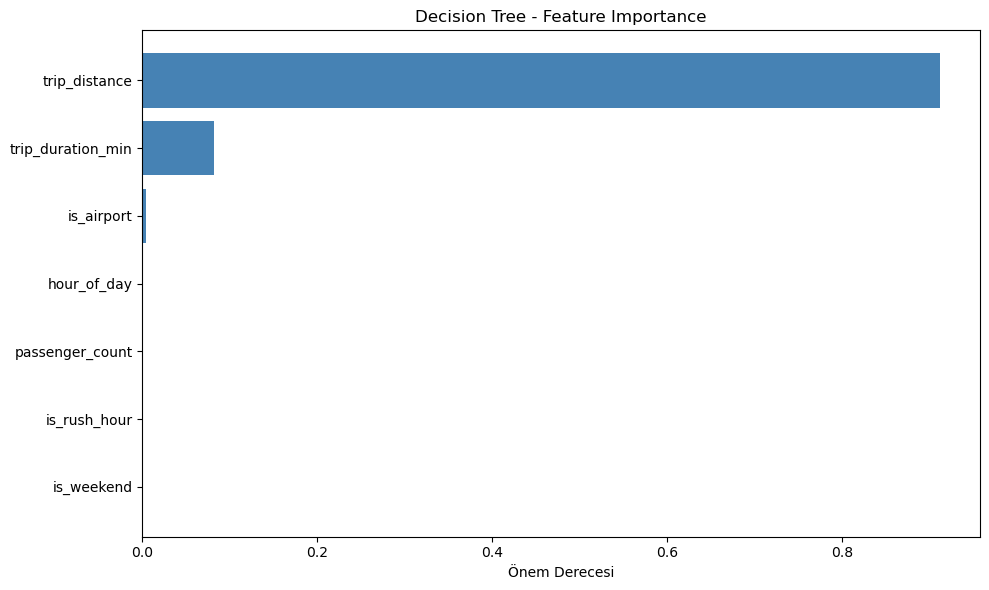

✅ Feature importance grafiği kaydedildi.


In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Feature importance
feature_importances = dt_model.featureImportances
importance_list = [(feature_cols[i], float(feature_importances[i])) for i in range(len(feature_cols))]
importance_df = pd.DataFrame(importance_list, columns=["Feature", "Importance"])
importance_df = importance_df.sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.title("Decision Tree - Feature Importance")
plt.xlabel("Önem Derecesi")
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dt_feature_importance.png")
plt.show()
print("✅ Feature importance grafiği kaydedildi.")

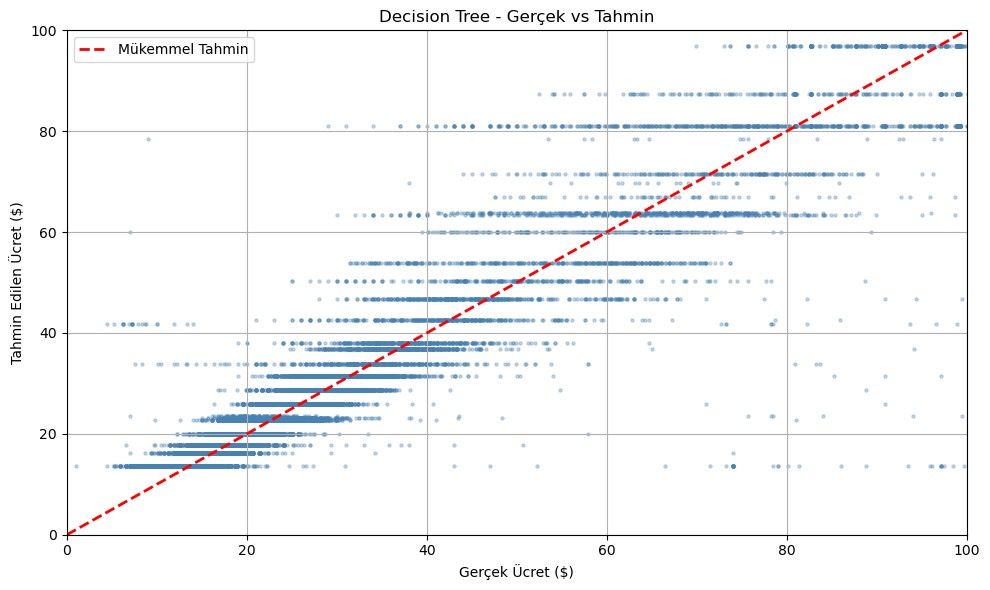

✅ Scatter plot kaydedildi.


In [12]:
# Gerçek vs Tahmin scatter plot
sample = predictions.select("total_amount", "prediction") \
    .sample(fraction=0.05) \
    .toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(sample["total_amount"], sample["prediction"], alpha=0.3, s=5, color="steelblue")
plt.plot([0, 100], [0, 100], color="red", linewidth=2, linestyle="--", label="Mükemmel Tahmin")
plt.title("Decision Tree - Gerçek vs Tahmin")
plt.xlabel("Gerçek Ücret ($)")
plt.ylabel("Tahmin Edilen Ücret ($)")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dt_actual_vs_predicted.png")
plt.show()
print("✅ Scatter plot kaydedildi.")